In [37]:
!pip install -q grad-cam torchmetrics

In [38]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/SDP_CISHA_05'
CKPT_DIR    = f'{PROJECT_DIR}/checkpoints'
RESULTS_DIR = f'{PROJECT_DIR}/results'

for d in [PROJECT_DIR, CKPT_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

print("Project directory ready at:", PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory ready at: /content/drive/MyDrive/SDP_CISHA_05


In [39]:
DATASET_ROOT = '/content/drive/MyDrive/Alzhimer_Dataset/Alzheimer_s Dataset'
TRAIN_DIR = os.path.join(DATASET_ROOT, 'train')
TEST_DIR  = os.path.join(DATASET_ROOT, 'test')

CLASSES = ['NonDemented', 'VeryMildDemented', 'MildDemented', 'ModerateDemented']

print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR :", TEST_DIR)
print("Exists?  :", os.path.exists(TRAIN_DIR), os.path.exists(TEST_DIR))

TRAIN_DIR: /content/drive/MyDrive/Alzhimer_Dataset/Alzheimer_s Dataset/train
TEST_DIR : /content/drive/MyDrive/Alzhimer_Dataset/Alzheimer_s Dataset/test
Exists?  : True True


In [40]:
import shutil, os

LOCAL_DATA_ROOT = '/content/local_data'
if not os.path.exists(LOCAL_DATA_ROOT):
    print("Copying dataset to local Colab disk (faster than reading from Drive each batch)...")
    shutil.copytree(DATASET_ROOT, f'{LOCAL_DATA_ROOT}/Alzheimer_s Dataset')
    shutil.copytree(AUGMENTED_ROOT, f'{LOCAL_DATA_ROOT}/data_augmented')
    print("Done.")
else:
    print("Local copy already exists.")

TRAIN_DIR = f'{LOCAL_DATA_ROOT}/Alzheimer_s Dataset/train'
TEST_DIR  = f'{LOCAL_DATA_ROOT}/Alzheimer_s Dataset/test'
dest_dir  = f'{LOCAL_DATA_ROOT}/data_augmented/{TARGET_CLASS}'

Local copy already exists.


In [41]:
import glob

IMG_EXTS = ('*.jpg', '*.jpeg', '*.png')

def count_images(folder):
    if not os.path.exists(folder):
        return -1
    n = 0
    for ext in IMG_EXTS:
        n += len(glob.glob(os.path.join(folder, ext)))
    return n

def show_class_counts(split_dir, split_name):
    print(f"\n--- {split_name} ---")
    counts = {}
    for cls in CLASSES:
        cls_path = os.path.join(split_dir, cls)
        n = count_images(cls_path)
        counts[cls] = n
        flag = " <-- EMPTY/MISSING" if n <= 0 else ""
        print(f"{cls:20s}: {n}{flag}")
    print(f"{'TOTAL':20s}: {sum(c for c in counts.values() if c > 0)}")
    return counts

train_counts = show_class_counts(TRAIN_DIR, "Train")
test_counts  = show_class_counts(TEST_DIR, "Test")


--- Train ---
NonDemented         : 3200
VeryMildDemented    : 2240
MildDemented        : 896
ModerateDemented    : 80
TOTAL               : 6416

--- Test ---
NonDemented         : 3216
VeryMildDemented    : 2241
MildDemented        : 896
ModerateDemented    : 57
TOTAL               : 6410


In [42]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np
import random
from collections import defaultdict, Counter

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

Device: cuda


In [43]:
IMG_SIZE = 224  # standard for ResNet/EfficientNet ImageNet weights

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],   # ImageNet stats
                          std=[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                          std=[0.229, 0.224, 0.225]),
])

In [44]:
random.seed(42)

AUGMENTED_ROOT = f'{PROJECT_DIR}/data_augmented'
os.makedirs(AUGMENTED_ROOT, exist_ok=True)

TARGET_CLASS = 'ModerateDemented'
MULTIPLIER = 6  # 80 originals -> ~480 augmented, closer to MildDemented's 896

source_dir = os.path.join(TRAIN_DIR, TARGET_CLASS)
dest_dir = os.path.join(AUGMENTED_ROOT, TARGET_CLASS)
os.makedirs(dest_dir, exist_ok=True)

# deliberately mild augmentation, medical-image appropriate
# no horizontal flip: brain hemisphere asymmetry can be diagnostically relevant
augment_pipeline = transforms.Compose([
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=0, translate=(0.08, 0.08), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
])

source_files = [f for f in os.listdir(source_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
print(f"Source images for {TARGET_CLASS}: {len(source_files)}")

existing_augmented = len(os.listdir(dest_dir))
if existing_augmented >= len(source_files) * MULTIPLIER:
    print(f"Augmented data already exists ({existing_augmented} files) — skipping regeneration.")
else:
    count = 0
    for fname in source_files:
        img_path = os.path.join(source_dir, fname)
        image = Image.open(img_path).convert('RGB')

        for i in range(MULTIPLIER):
            aug_image = augment_pipeline(image)
            base_name = os.path.splitext(fname)[0]
            save_path = os.path.join(dest_dir, f"{base_name}_aug{i}.jpg")
            aug_image.save(save_path, quality=95)
            count += 1

    print(f"Generated {count} augmented images for {TARGET_CLASS} at {dest_dir}")

print(f"\nTotal {TARGET_CLASS} images now available: {len(source_files)} original + {len(os.listdir(dest_dir))} augmented")

Source images for ModerateDemented: 80
Augmented data already exists (480 files) — skipping regeneration.

Total ModerateDemented images now available: 80 original + 480 augmented


In [45]:
class MergedImageFolder(Dataset):
    def __init__(self, primary_root, extra_class_dir, extra_class_name, classes, transform):
        self.transform = transform
        self.classes = classes
        self.class_to_idx = {cls: i for i, cls in enumerate(classes)}
        self.samples = []

        # primary data (all classes, from original TRAIN_DIR)
        for cls in classes:
            cls_folder = os.path.join(primary_root, cls)
            for fname in os.listdir(cls_folder):
                if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                    self.samples.append((os.path.join(cls_folder, fname), self.class_to_idx[cls]))

        # extra augmented data (only for the minority class)
        if extra_class_dir is not None:
            for fname in os.listdir(extra_class_dir):
                if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                    self.samples.append((os.path.join(extra_class_dir, fname), self.class_to_idx[extra_class_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert('RGB')
        image = self.transform(image)
        return image, label


full_train_dataset = MergedImageFolder(
    primary_root=TRAIN_DIR,
    extra_class_dir=dest_dir,
    extra_class_name=TARGET_CLASS,
    classes=CLASSES,
    transform=train_transform
)

test_dataset = MergedImageFolder(
    primary_root=TEST_DIR,
    extra_class_dir=None,
    extra_class_name=None,
    classes=CLASSES,
    transform=eval_transform
)

print("Merged train dataset size:", len(full_train_dataset))
print("Test dataset size:", len(test_dataset))

label_counts = Counter(label for _, label in full_train_dataset.samples)
print("Per-class counts after merge:", {CLASSES[k]: v for k, v in sorted(label_counts.items())})

Merged train dataset size: 6896
Test dataset size: 6410
Per-class counts after merge: {'NonDemented': 3200, 'VeryMildDemented': 2240, 'MildDemented': 896, 'ModerateDemented': 560}


In [46]:
VAL_FRACTION = 0.15

class_indices = defaultdict(list)
for idx, (_, label) in enumerate(full_train_dataset.samples):
    class_indices[label].append(idx)

train_idx, val_idx = [], []
for label, indices in class_indices.items():
    random.shuffle(indices)
    n_val = max(1, int(len(indices) * VAL_FRACTION))  # at least 1 val sample per class
    val_idx.extend(indices[:n_val])
    train_idx.extend(indices[n_val:])

print(f"Train subset: {len(train_idx)} | Val subset: {len(val_idx)}")

train_subset = torch.utils.data.Subset(full_train_dataset, train_idx)
val_subset_raw = torch.utils.data.Subset(full_train_dataset, val_idx)


class TransformWrapper(Dataset):
    """Val subset must use eval_transform (no augmentation)."""
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        parent_dataset = self.subset.dataset
        real_idx = self.subset.indices[idx]
        path, label = parent_dataset.samples[real_idx]
        image = Image.open(path).convert('RGB')
        image = self.transform(image)
        return image, label


val_subset = TransformWrapper(val_subset_raw, eval_transform)

Train subset: 5862 | Val subset: 1034


In [47]:
train_labels = [full_train_dataset.samples[i][1] for i in train_idx]
class_sample_counts = np.bincount(train_labels, minlength=len(CLASSES))
print("Train subset class counts (post-augmentation):", dict(zip(CLASSES, class_sample_counts)))

class_weights_for_loss = torch.tensor(
    class_sample_counts.sum() / (len(class_sample_counts) * class_sample_counts),
    dtype=torch.float32
).to(device)

print("Class weights for CrossEntropyLoss:", dict(zip(CLASSES, class_weights_for_loss.cpu().numpy())))

criterion = nn.CrossEntropyLoss(weight=class_weights_for_loss)

Train subset class counts (post-augmentation): {'NonDemented': np.int64(2720), 'VeryMildDemented': np.int64(1904), 'MildDemented': np.int64(762), 'ModerateDemented': np.int64(476)}
Class weights for CrossEntropyLoss: {'NonDemented': np.float32(0.53878677), 'VeryMildDemented': np.float32(0.7696954), 'MildDemented': np.float32(1.9232284), 'ModerateDemented': np.float32(3.0787816)}


In [48]:
BATCH_SIZE = 32

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Batches — train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")

Batches — train: 184, val: 33, test: 201


In [49]:
from torchvision import models

def build_model(num_classes=4):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    # replace final FC layer for our 4-class problem
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model

model = build_model(num_classes=len(CLASSES)).to(device)
print(model.fc)

Linear(in_features=512, out_features=4, bias=True)


In [50]:
def set_backbone_frozen(model, freeze=True):
    for name, param in model.named_parameters():
        if not name.startswith('fc'):
            param.requires_grad = not freeze

set_backbone_frozen(model, freeze=True)

trainable_params = [p for p in model.parameters() if p.requires_grad]
print(f"Trainable parameters (Phase 1): {sum(p.numel() for p in trainable_params):,}")

optimizer = torch.optim.AdamW(trainable_params, lr=1e-3, weight_decay=1e-4)


Trainable parameters (Phase 1): 2,052


In [51]:
from sklearn.metrics import f1_score, accuracy_score

def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    all_preds, all_labels = [], []

    with torch.set_grad_enabled(is_train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            if is_train:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_train:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(all_labels, all_preds, average='macro')
    return avg_loss, acc, macro_f1


In [52]:
best_val_f1 = 0.0
CKPT_PATH = f'{CKPT_DIR}/best_resnet18.pth'

def save_if_best(model, val_f1, epoch, phase):
    global best_val_f1
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save({
            'model_state_dict': model.state_dict(),
            'epoch': epoch,
            'phase': phase,
            'val_f1': val_f1,
        }, CKPT_PATH)
        print(f"  -> New best model saved (val macro-F1: {val_f1:.4f})")

In [53]:
PHASE1_EPOCHS = 5

for epoch in range(1, PHASE1_EPOCHS + 1):
    train_loss, train_acc, train_f1 = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc, val_f1 = run_epoch(model, val_loader, criterion)

    print(f"[Phase 1 | Epoch {epoch}/{PHASE1_EPOCHS}] "
          f"train_loss={train_loss:.4f} train_f1={train_f1:.4f} | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} val_f1={val_f1:.4f}")

    save_if_best(model, val_f1, epoch, phase='phase1')

[Phase 1 | Epoch 1/5] train_loss=1.1777 train_f1=0.4185 | val_loss=0.9984 val_acc=0.5445 val_f1=0.5097
  -> New best model saved (val macro-F1: 0.5097)
[Phase 1 | Epoch 2/5] train_loss=1.0269 train_f1=0.4938 | val_loss=0.9500 val_acc=0.5890 val_f1=0.5751
  -> New best model saved (val macro-F1: 0.5751)
[Phase 1 | Epoch 3/5] train_loss=0.9663 train_f1=0.5222 | val_loss=0.9956 val_acc=0.5135 val_f1=0.4991
[Phase 1 | Epoch 4/5] train_loss=0.9468 train_f1=0.5394 | val_loss=1.0684 val_acc=0.5097 val_f1=0.5411
[Phase 1 | Epoch 5/5] train_loss=0.9177 train_f1=0.5560 | val_loss=1.0213 val_acc=0.5145 val_f1=0.5560


In [54]:
# unfreeze layer4 (last residual block) + fc; keep earlier layers frozen
# to preserve low-level ImageNet features and reduce overfitting risk
# given our relatively small dataset
for name, param in model.named_parameters():
    if name.startswith('layer4') or name.startswith('fc'):
        param.requires_grad = True
    else:
        param.requires_grad = False

trainable_params = [p for p in model.parameters() if p.requires_grad]
print(f"Trainable parameters (Phase 2): {sum(p.numel() for p in trainable_params):,}")

optimizer = torch.optim.AdamW(trainable_params, lr=1e-4, weight_decay=1e-4)  # 10x lower LR
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

PHASE2_EPOCHS = 12
patience_counter = 0
EARLY_STOP_PATIENCE = 4

for epoch in range(1, PHASE2_EPOCHS + 1):
    train_loss, train_acc, train_f1 = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc, val_f1 = run_epoch(model, val_loader, criterion)

    print(f"[Phase 2 | Epoch {epoch}/{PHASE2_EPOCHS}] "
          f"train_loss={train_loss:.4f} train_f1={train_f1:.4f} | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} val_f1={val_f1:.4f}")

    prev_best = best_val_f1
    save_if_best(model, val_f1, epoch, phase='phase2')
    scheduler.step(val_f1)

    if val_f1 > prev_best:
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= EARLY_STOP_PATIENCE:
            print(f"Early stopping — no val macro-F1 improvement in {EARLY_STOP_PATIENCE} epochs.")
            break

print(f"\nTraining complete. Best val macro-F1: {best_val_f1:.4f}")
print(f"Best checkpoint saved at: {CKPT_PATH}")

Trainable parameters (Phase 2): 8,395,780
[Phase 2 | Epoch 1/12] train_loss=0.7659 train_f1=0.6164 | val_loss=0.8225 val_acc=0.6296 val_f1=0.6788
  -> New best model saved (val macro-F1: 0.6788)
[Phase 2 | Epoch 2/12] train_loss=0.5862 train_f1=0.7146 | val_loss=0.6146 val_acc=0.7369 val_f1=0.7677
  -> New best model saved (val macro-F1: 0.7677)
[Phase 2 | Epoch 3/12] train_loss=0.5066 train_f1=0.7554 | val_loss=0.5368 val_acc=0.7640 val_f1=0.8021
  -> New best model saved (val macro-F1: 0.8021)
[Phase 2 | Epoch 4/12] train_loss=0.4323 train_f1=0.7957 | val_loss=0.4947 val_acc=0.7901 val_f1=0.8170
  -> New best model saved (val macro-F1: 0.8170)
[Phase 2 | Epoch 5/12] train_loss=0.3669 train_f1=0.8330 | val_loss=0.6426 val_acc=0.7553 val_f1=0.7812
[Phase 2 | Epoch 6/12] train_loss=0.3326 train_f1=0.8471 | val_loss=0.6431 val_acc=0.7524 val_f1=0.7748
[Phase 2 | Epoch 7/12] train_loss=0.3065 train_f1=0.8571 | val_loss=0.4445 val_acc=0.8182 val_f1=0.8490
  -> New best model saved (val mac

In [55]:
# ============================================================
# Resume Phase 2 training from the last checkpoint for more epochs
# ============================================================
checkpoint = torch.load(CKPT_PATH)
model.load_state_dict(checkpoint['model_state_dict'])
best_val_f1 = checkpoint['val_f1']
print(f"Resumed from checkpoint — epoch {checkpoint['epoch']}, val_f1={best_val_f1:.4f}")

# keep the same layer4+fc unfrozen setup, fresh optimizer state is fine
optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=5e-5,  # slightly lower than before, since we're continuing a converging run
    weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

EXTRA_EPOCHS = 15
patience_counter = 0
EARLY_STOP_PATIENCE = 5  # slightly more patient this round since it's still climbing

for epoch in range(1, EXTRA_EPOCHS + 1):
    train_loss, train_acc, train_f1 = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc, val_f1 = run_epoch(model, val_loader, criterion)

    print(f"[Phase 2 continued | Epoch {epoch}/{EXTRA_EPOCHS}] "
          f"train_loss={train_loss:.4f} train_f1={train_f1:.4f} | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} val_f1={val_f1:.4f}")

    prev_best = best_val_f1
    save_if_best(model, val_f1, epoch, phase='phase2_continued')
    scheduler.step(val_f1)

    if val_f1 > prev_best:
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= EARLY_STOP_PATIENCE:
            print(f"Early stopping — no val macro-F1 improvement in {EARLY_STOP_PATIENCE} epochs.")
            break

print(f"\nContinued training complete. Best val macro-F1: {best_val_f1:.4f}")

Resumed from checkpoint — epoch 12, val_f1=0.9301
[Phase 2 continued | Epoch 1/15] train_loss=0.1369 train_f1=0.9414 | val_loss=0.1505 val_acc=0.9449 val_f1=0.9531
  -> New best model saved (val macro-F1: 0.9531)
[Phase 2 continued | Epoch 2/15] train_loss=0.1168 train_f1=0.9518 | val_loss=0.1551 val_acc=0.9420 val_f1=0.9462
[Phase 2 continued | Epoch 3/15] train_loss=0.1078 train_f1=0.9571 | val_loss=0.1236 val_acc=0.9545 val_f1=0.9628
  -> New best model saved (val macro-F1: 0.9628)
[Phase 2 continued | Epoch 4/15] train_loss=0.1068 train_f1=0.9523 | val_loss=0.1498 val_acc=0.9468 val_f1=0.9570
[Phase 2 continued | Epoch 5/15] train_loss=0.1027 train_f1=0.9582 | val_loss=0.1871 val_acc=0.9304 val_f1=0.9335
[Phase 2 continued | Epoch 6/15] train_loss=0.0942 train_f1=0.9601 | val_loss=0.1077 val_acc=0.9632 val_f1=0.9673
  -> New best model saved (val macro-F1: 0.9673)
[Phase 2 continued | Epoch 7/15] train_loss=0.0898 train_f1=0.9617 | val_loss=0.1366 val_acc=0.9497 val_f1=0.9579
[Phas

In [57]:
from PIL import Image
import os

def scan_for_corrupted(root_dir):
    corrupted = []
    for dirpath, _, filenames in os.walk(root_dir):
        for fname in filenames:
            if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                fpath = os.path.join(dirpath, fname)
                try:
                    with Image.open(fpath) as img:
                        img.verify()  # checks integrity without fully decoding
                except Exception as e:
                    corrupted.append(fpath)
    return corrupted

corrupted_files = scan_for_corrupted(LOCAL_DATA_ROOT)
print(f"Found {len(corrupted_files)} corrupted file(s):")
for f in corrupted_files:
    print(" -", f)

Found 1 corrupted file(s):
 - /content/local_data/Alzheimer_s Dataset/test/ModerateDemented/moderate_2.jpg


In [58]:
import shutil

local_path = '/content/local_data/Alzheimer_s Dataset/test/ModerateDemented/moderate_2.jpg'
drive_path = '/content/drive/MyDrive/Alzhimer_Dataset/Alzheimer_s Dataset/test/ModerateDemented/moderate_2.jpg'

print("Source exists:", os.path.exists(drive_path))
shutil.copy2(drive_path, local_path)

# verify it's readable now
from PIL import Image
try:
    with Image.open(local_path) as img:
        img.verify()
    print("File is now valid.")
except Exception as e:
    print("Still corrupted:", e)

Source exists: True
File is now valid.


In [59]:
test_loss, test_acc, test_f1 = run_epoch(model, test_loader, criterion)
print(f"\nTest set — loss: {test_loss:.4f}, accuracy: {test_acc:.4f}, macro-F1: {test_f1:.4f}")



Test set — loss: 0.0267, accuracy: 0.9927, macro-F1: 0.9947



Classification Report:

                  precision    recall  f1-score   support

     NonDemented     0.9938    0.9928    0.9933      3216
VeryMildDemented     0.9919    0.9893    0.9906      2241
    MildDemented     0.9901    1.0000    0.9950       896
ModerateDemented     1.0000    1.0000    1.0000        57

        accuracy                         0.9927      6410
       macro avg     0.9939    0.9955    0.9947      6410
    weighted avg     0.9927    0.9927    0.9927      6410



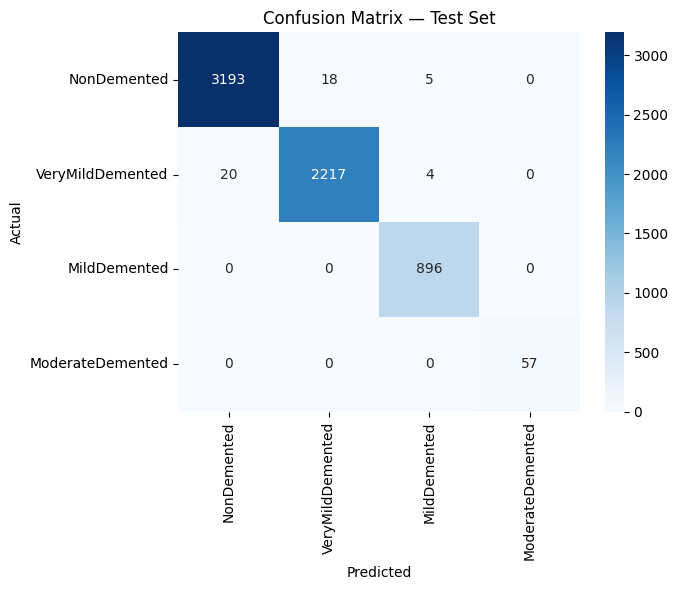

In [60]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

all_preds, all_labels = [], []
model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds, target_names=CLASSES, digits=4))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — Test Set')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/confusion_matrix.png', dpi=150)
plt.show()

In [63]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch

model.eval()

# ResNet18's last conv block — standard target layer for Grad-CAM
target_layers = [model.layer4[-1]]
cam = GradCAM(model=model, target_layers=target_layers)

# reverse the normalization for display purposes
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD  = np.array([0.229, 0.224, 0.225])

def denormalize(tensor_img):
    img = tensor_img.cpu().numpy().transpose(1, 2, 0)
    img = img * IMAGENET_STD + IMAGENET_MEAN
    img = np.clip(img, 0, 1)
    return img

def run_gradcam_on_sample(image_tensor, true_label, pred_label=None):
    input_tensor = image_tensor.unsqueeze(0).to(device)
    grayscale_cam = cam(input_tensor=input_tensor, targets=None)[0]  # None = uses model's top predicted class

    rgb_img = denormalize(image_tensor)
    visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)
    return rgb_img, visualization

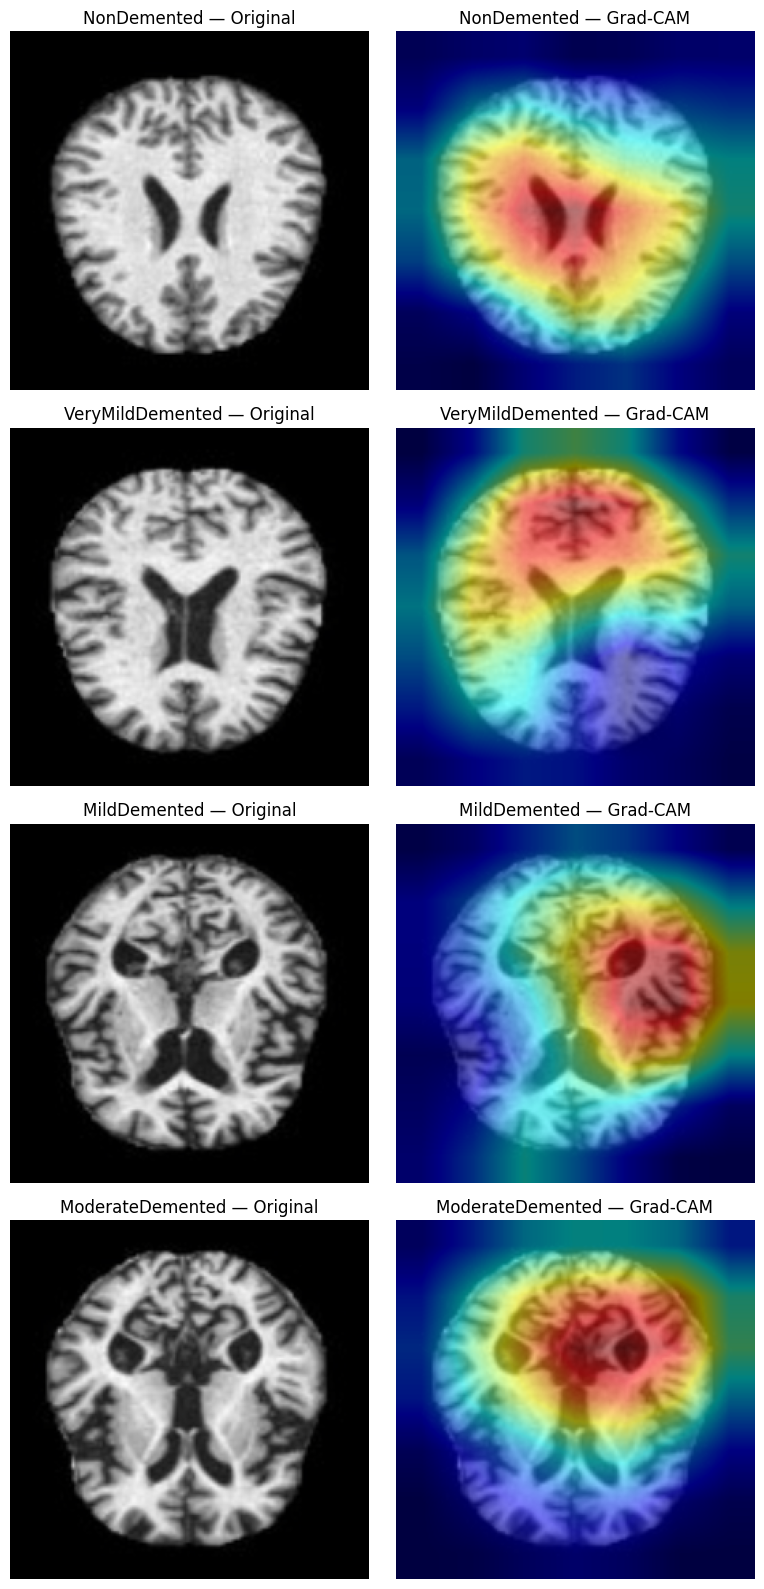

In [64]:
model.eval()
samples_per_class = {}

with torch.no_grad():
    for images, labels in test_loader:
        images_gpu = images.to(device)
        outputs = model(images_gpu)
        preds = outputs.argmax(dim=1).cpu()

        for img, true_lbl, pred_lbl in zip(images, labels, preds):
            true_lbl = true_lbl.item()
            pred_lbl = pred_lbl.item()
            if true_lbl == pred_lbl and true_lbl not in samples_per_class:
                samples_per_class[true_lbl] = img
        if len(samples_per_class) == len(CLASSES):
            break

fig, axes = plt.subplots(len(CLASSES), 2, figsize=(8, 4 * len(CLASSES)))

for i, cls_idx in enumerate(sorted(samples_per_class.keys())):
    img_tensor = samples_per_class[cls_idx]
    rgb_img, cam_overlay = run_gradcam_on_sample(img_tensor, cls_idx)

    axes[i, 0].imshow(rgb_img)
    axes[i, 0].set_title(f"{CLASSES[cls_idx]} — Original")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(cam_overlay)
    axes[i, 1].set_title(f"{CLASSES[cls_idx]} — Grad-CAM")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/gradcam_per_class.png', dpi=150)
plt.show()

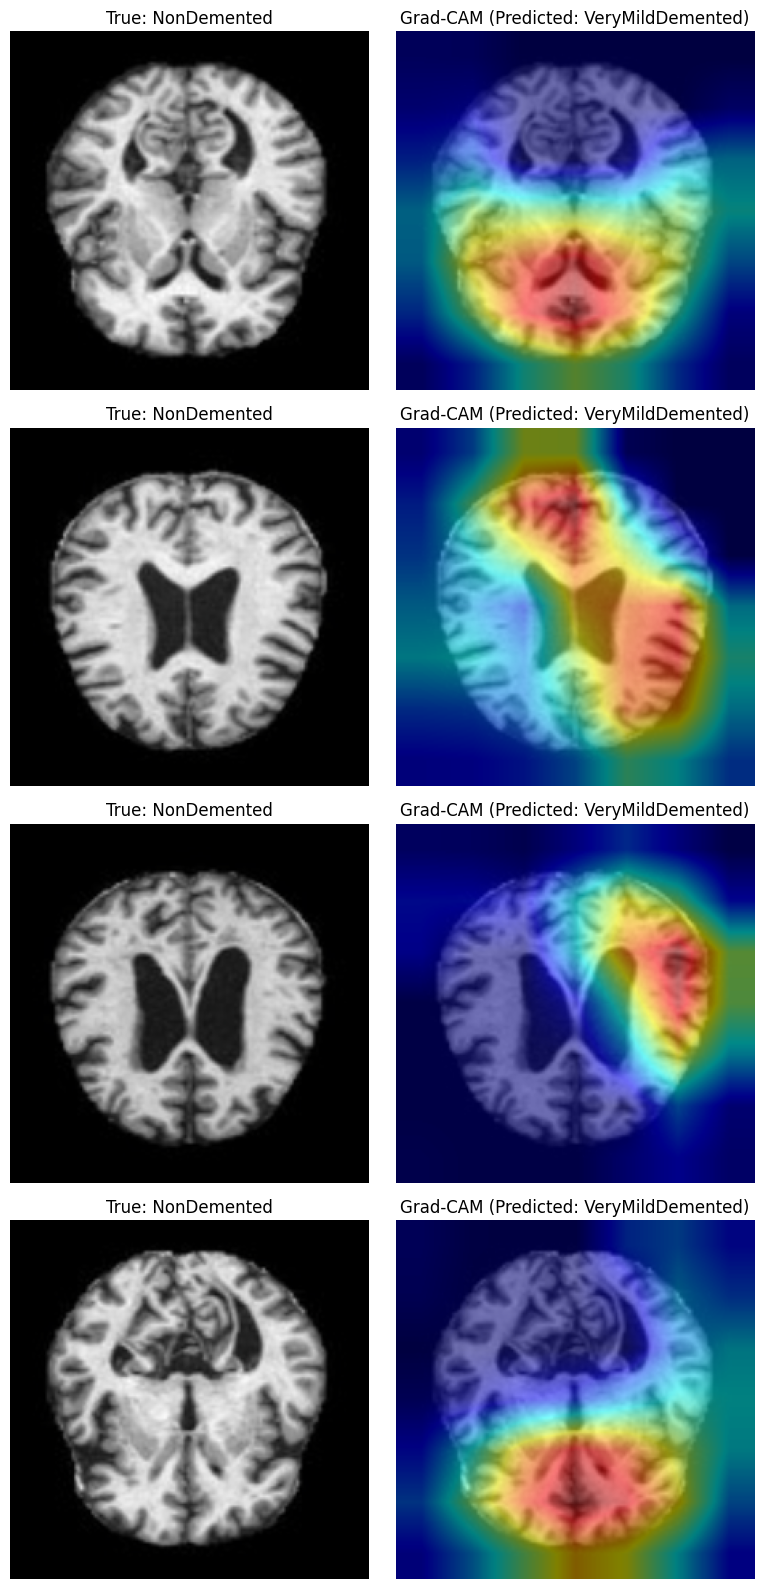

Found and visualized 4 misclassified example(s).


In [65]:
misclassified = []

with torch.no_grad():
    for images, labels in test_loader:
        images_gpu = images.to(device)
        outputs = model(images_gpu)
        preds = outputs.argmax(dim=1).cpu()

        for img, true_lbl, pred_lbl in zip(images, labels, preds):
            if true_lbl.item() != pred_lbl.item():
                misclassified.append((img, true_lbl.item(), pred_lbl.item()))
        if len(misclassified) >= 4:
            break

if misclassified:
    fig, axes = plt.subplots(len(misclassified), 2, figsize=(8, 4 * len(misclassified)))
    if len(misclassified) == 1:
        axes = axes.reshape(1, -1)

    for i, (img_tensor, true_lbl, pred_lbl) in enumerate(misclassified):
        rgb_img, cam_overlay = run_gradcam_on_sample(img_tensor, true_lbl)

        axes[i, 0].imshow(rgb_img)
        axes[i, 0].set_title(f"True: {CLASSES[true_lbl]}")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(cam_overlay)
        axes[i, 1].set_title(f"Grad-CAM (Predicted: {CLASSES[pred_lbl]})")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/gradcam_misclassified.png', dpi=150)
    plt.show()
    print(f"Found and visualized {len(misclassified)} misclassified example(s).")
else:
    print("No misclassified examples found in the scanned batches (model performing very well, consistent with earlier metrics).")

In [66]:
import json

# Save classification report as text
report_text = classification_report(all_labels, all_preds, target_names=CLASSES, digits=4)
with open(f'{RESULTS_DIR}/classification_report.txt', 'w') as f:
    f.write(f"Test set — loss: {test_loss:.4f}, accuracy: {test_acc:.4f}, macro-F1: {test_f1:.4f}\n\n")
    f.write(report_text)

# Save a summary JSON with key metrics + training history for your report
summary = {
    "model": "ResNet18 (ImageNet pretrained, fine-tuned)",
    "classes": CLASSES,
    "best_val_macro_f1": best_val_f1,
    "test_accuracy": test_acc,
    "test_macro_f1": test_f1,
    "test_loss": test_loss,
    "imbalance_strategy": "Offline augmentation (6x) for ModerateDemented + weighted CrossEntropyLoss",
    "known_limitation": "Kaggle dataset documented to contain near-duplicate images across train/test splits; test metrics should be read as dataset-specific upper bound, not real-world generalization estimate."
}
with open(f'{RESULTS_DIR}/results_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print("Saved:")
print(f"  - {RESULTS_DIR}/confusion_matrix.png")
print(f"  - {RESULTS_DIR}/gradcam_per_class.png")
print(f"  - {RESULTS_DIR}/gradcam_misclassified.png")
print(f"  - {RESULTS_DIR}/classification_report.txt")
print(f"  - {RESULTS_DIR}/results_summary.json")
print(f"\nAll results saved in: {RESULTS_DIR}")

Saved:
  - /content/drive/MyDrive/SDP_CISHA_05/results/confusion_matrix.png
  - /content/drive/MyDrive/SDP_CISHA_05/results/gradcam_per_class.png
  - /content/drive/MyDrive/SDP_CISHA_05/results/gradcam_misclassified.png
  - /content/drive/MyDrive/SDP_CISHA_05/results/classification_report.txt
  - /content/drive/MyDrive/SDP_CISHA_05/results/results_summary.json

All results saved in: /content/drive/MyDrive/SDP_CISHA_05/results


In [67]:
import json

# Save classification report as text
report_text = classification_report(all_labels, all_preds, target_names=CLASSES, digits=4)
with open(f'{RESULTS_DIR}/classification_report.txt', 'w') as f:
    f.write(f"Test set — loss: {test_loss:.4f}, accuracy: {test_acc:.4f}, macro-F1: {test_f1:.4f}\n\n")
    f.write(report_text)

# Save a summary JSON with key metrics + training history for your report
summary = {
    "model": "ResNet18 (ImageNet pretrained, fine-tuned)",
    "classes": CLASSES,
    "best_val_macro_f1": best_val_f1,
    "test_accuracy": test_acc,
    "test_macro_f1": test_f1,
    "test_loss": test_loss,
    "imbalance_strategy": "Offline augmentation (6x) for ModerateDemented + weighted CrossEntropyLoss",
    "known_limitation": "Kaggle dataset documented to contain near-duplicate images across train/test splits; test metrics should be read as dataset-specific upper bound, not real-world generalization estimate."
}
with open(f'{RESULTS_DIR}/results_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print("Saved:")
print(f"  - {RESULTS_DIR}/confusion_matrix.png")
print(f"  - {RESULTS_DIR}/gradcam_per_class.png")
print(f"  - {RESULTS_DIR}/gradcam_misclassified.png")
print(f"  - {RESULTS_DIR}/classification_report.txt")
print(f"  - {RESULTS_DIR}/results_summary.json")
print(f"\nAll results saved in: {RESULTS_DIR}")

Saved:
  - /content/drive/MyDrive/SDP_CISHA_05/results/confusion_matrix.png
  - /content/drive/MyDrive/SDP_CISHA_05/results/gradcam_per_class.png
  - /content/drive/MyDrive/SDP_CISHA_05/results/gradcam_misclassified.png
  - /content/drive/MyDrive/SDP_CISHA_05/results/classification_report.txt
  - /content/drive/MyDrive/SDP_CISHA_05/results/results_summary.json

All results saved in: /content/drive/MyDrive/SDP_CISHA_05/results


In [68]:
!pip install -q huggingface_hub

from huggingface_hub import login
login()  # paste your HF access token when prompted (create one at huggingface.co/settings/tokens with "write" access)


In [71]:
from huggingface_hub import whoami
print(whoami())


{'type': 'user', 'id': '6a91ab0b1e294a43cfbbb7ad', 'name': 'the7prajwal', 'fullname': 'Prajwal Halakeri', 'email': 'the7prajwal@gmail.com', 'emailVerified': True, 'canPay': False, 'billingMode': 'prepaid', 'periodEnd': 1788220800, 'isPro': False, 'avatarUrl': '/avatars/c57a3ab22895b4bc01877160d784b4df.svg', 'orgs': [], 'auth': {'type': 'access_token', 'accessToken': {'displayName': 'alzheimer-classifier', 'role': 'write', 'createdAt': '2026-08-29T10:33:34.678Z'}}}


In [73]:
import json
import torch

HF_EXPORT_DIR = f'{PROJECT_DIR}/hf_export'
os.makedirs(HF_EXPORT_DIR, exist_ok=True)

# Save just the model weights (cleaner than the full training checkpoint)
final_checkpoint = torch.load(CKPT_PATH)
torch.save(final_checkpoint['model_state_dict'], f'{HF_EXPORT_DIR}/pytorch_model.bin')

# Save a config so anyone loading this model knows the architecture + classes
model_config = {
    "architecture": "resnet18",
    "num_classes": len(CLASSES),
    "classes": CLASSES,
    "input_size": IMG_SIZE,
    "normalization_mean": [0.485, 0.456, 0.406],
    "normalization_std": [0.229, 0.224, 0.225],
    "task": "Alzheimer's stage classification from brain MRI (4-class)",
}
with open(f'{HF_EXPORT_DIR}/config.json', 'w') as f:
    json.dump(model_config, f, indent=2)

print("Export files ready at:", HF_EXPORT_DIR)
print(os.listdir(HF_EXPORT_DIR))

Export files ready at: /content/drive/MyDrive/SDP_CISHA_05/hf_export
['pytorch_model.bin', 'config.json']


In [74]:
model_card = f"""---
license: mit
tags:
- medical-imaging
- alzheimer
- mri
- image-classification
- pytorch
---

# Alzheimer's Stage Detection from Brain MRI (ResNet18)

Fine-tuned ResNet18 for 4-class Alzheimer's stage classification from axial brain MRI slices.
Developed as part of SDP_CISHA_05 (7th semester Student Development Project).

## Classes
{chr(10).join(f'- {c}' for c in CLASSES)}

## Training Details
- **Backbone**: ResNet18, ImageNet-pretrained, fine-tuned in 2 phases (frozen head warmup, then unfrozen layer4 + fc)
- **Dataset**: Kaggle Alzheimer's Dataset (4-class, ~6400 images)
- **Class imbalance handling**: Offline augmentation (6x) applied to the minority ModerateDemented class + weighted CrossEntropyLoss
- **Best validation macro-F1**: {best_val_f1:.4f}
- **Test set accuracy**: {test_acc:.4f}
- **Test set macro-F1**: {test_f1:.4f}

## ⚠️ Important Limitations
- **Dataset leakage**: This Kaggle dataset is documented in academic literature to contain near-duplicate/augmented images shared across its train and test splits. Reported test metrics should be interpreted as a **dataset-specific upper bound**, not an estimate of real-world generalization to independent clinical scans.
- **Not for clinical use**: This model is an academic/educational project and has NOT been validated on independent clinical data, reviewed by medical professionals, or approved for diagnostic use. It must not be used to inform real medical decisions.
- **Explainability**: Grad-CAM visualizations indicate the model attends to anatomically relevant regions (ventricles, periventricular cortex) rather than scan artifacts, but this does not substitute for clinical validation.

## Intended Use
Educational and research demonstration of transfer learning + explainable AI (Grad-CAM) applied to medical image classification.
"""

with open(f'{HF_EXPORT_DIR}/README.md', 'w') as f:
    f.write(model_card)

print("Model card written.")

Model card written.


In [75]:
from huggingface_hub import HfApi, create_repo

HF_USERNAME = "the7prajwal"
REPO_NAME = "alzheimer-stage-resnet18"
REPO_ID = f"{HF_USERNAME}/{REPO_NAME}"

create_repo(REPO_ID, exist_ok=True)

api = HfApi()
api.upload_folder(
    folder_path=HF_EXPORT_DIR,
    repo_id=REPO_ID,
    repo_type="model"
)

print(f"\n✅ Model uploaded: https://huggingface.co/{REPO_ID}")


✅ Model uploaded: https://huggingface.co/the7prajwal/alzheimer-stage-resnet18
